# Buổi F4: PCA, nén 64 cột xuống vài cột mà vẫn giữ được ý chính

**Hiện trường.** Chị Hạnh có ảnh chữ số viết tay, mỗi ảnh 8x8 điểm ảnh, tức **64 cột**. Bảng 64 cột thì không vẽ được, khó nhìn, và nhiều cột gần như nói cùng một chuyện (điểm ảnh cạnh nhau thường sáng cùng nhau). Chị hỏi: *có cách nào nén 64 cột xuống 2 đến 20 cột mà vẫn giữ được phần lớn thông tin?*

Buổi này dạy **PCA** (*principal component analysis*, phân tích thành phần chính): tìm những **hướng mới** trong dữ liệu sao cho dữ liệu **trải dài nhất** theo các hướng đó, rồi chỉ giữ vài hướng đầu.

**Ẩn dụ:** chụp một chiếc bàn dài từ góc nào thì thấy rõ nhất hình dạng của nó? Từ trên xuống, dọc theo chiều dài. PCA là cách tìm "góc chụp" tốt nhất, rồi tìm tiếp góc tốt thứ hai vuông góc với góc đầu, và cứ thế.

**Mindset của người làm dữ liệu:** nén luôn mất mát. Câu hỏi đúng là *mất bao nhiêu* và *phần mất có quan trọng cho việc mình làm không*.

**Lưu ý:** dữ liệu `digits` và `wine` của sklearn, dùng để học.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Thấy ngay: 64 cột nén thành 2 và vẽ được |
| Chặng 1 | PCA bằng tay: tâm hóa, hiệp phương sai, hướng riêng |
| Chặng 2 | Giữ bao nhiêu hướng: phương sai giải thích được |
| Chặng 3 | Dựng lại ảnh từ ít hướng: nhìn tận mắt phần mất |
| Chặng 4 | Bẫy thang đo: cột to lấn cột nhỏ |
| Chặng 5 | PCA làm bước tiền xử lý cho mô hình |

## Chặng 0: Thấy ngay, 64 cột thành 2

**Câu hỏi:** nén ảnh chữ số xuống 2 chiều thì còn thấy gì?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

shape before: (1797, 64) | after: (1797, 2)
share of variance kept by the 2 directions: [0.149 0.136] | total: 0.285


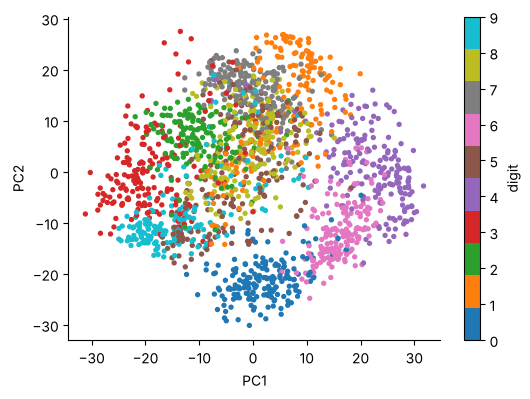

In [2]:
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
digits = load_digits()
X, y = digits.data, digits.target
pca2 = PCA(n_components=2).fit(X)
Z2 = pca2.transform(X)
print("shape before:", X.shape, "| after:", Z2.shape)
print("share of variance kept by the 2 directions:", pca2.explained_variance_ratio_.round(3), "| total:", round(pca2.explained_variance_ratio_.sum(), 3))
fig, ax = plt.subplots(figsize=(6, 4.2))
sc = ax.scatter(Z2[:, 0], Z2[:, 1], c=y, cmap="tab10", s=8)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); plt.colorbar(sc, label="digit")
plt.show()

**Giải thích từng dòng**

- `load_digits()`: 1797 ảnh chữ số 8x8, mỗi ảnh trải thành 64 số (độ sáng từng điểm ảnh).
- `PCA(n_components=2)`: giữ 2 hướng chính.
- `.fit(X)`: PCA **không dùng nhãn `y`**. Nó chỉ nhìn hình dạng đám mây dữ liệu. Đây là học không giám sát.
- `pca2.transform(X)`: chiếu mỗi ảnh lên 2 hướng, ra 2 số mỗi ảnh (`PC1`, `PC2`).
- `explained_variance_ratio_`: tỷ lệ "độ trải" của dữ liệu mà mỗi hướng giữ lại.

**Cách đọc.**
- **Con số:** từ **64** cột xuống **2** cột, giữ lại **28,5%** độ trải (PC1 **14,9%**, PC2 **13,6%**).
- **Bức tranh:** dù PCA không hề thấy nhãn, các chữ số cùng loại vẫn tụ lại thành mảng màu; nhiều mảng chồng lên nhau vì 2 hướng chưa đủ để tách mọi chữ số.
- **Câu hỏi tiếp:** hai hướng đó tìm ra bằng cách nào?

**Mang về chặng 1:** PCA tìm các hướng mà dữ liệu trải dài nhất; không cần nhãn.

## Chặng 1: PCA bằng tay

**Câu hỏi:** "hướng trải dài nhất" là phép tính gì?

In [3]:
Xc = X - X.mean(axis=0)
cov = np.cov(Xc, rowvar=False)
eigval, eigvec = np.linalg.eigh(cov)
order = np.argsort(eigval)[::-1]
eigval, eigvec = eigval[order], eigvec[:, order]
mine = Xc @ eigvec[:, :2]
print("explained ratio, mine   :", (eigval[:2] / eigval.sum()).round(4))
print("explained ratio, sklearn:", pca2.explained_variance_ratio_.round(4))
print("projections equal up to sign:", bool(np.allclose(np.abs(mine), np.abs(Z2), atol=1e-6)))
print("directions are perpendicular (dot of PC1, PC2):", round(float(eigvec[:, 0] @ eigvec[:, 1]), 10))

explained ratio, mine   : [0.1489 0.1362]
explained ratio, sklearn: [0.1489 0.1362]
projections equal up to sign: True
directions are perpendicular (dot of PC1, PC2): -0.0


**Giải thích từng dòng**

- `X - X.mean(axis=0)`: **tâm hóa**: trừ trung bình mỗi cột, để đám mây dữ liệu nằm quanh gốc tọa độ.
- `np.cov(Xc, rowvar=False)`: ma trận 64 x 64 cho biết từng cặp cột **cùng tăng cùng giảm** nhiều hay ít.
- `np.linalg.eigh(cov)`: tìm các **hướng riêng** (eigenvectors) và độ trải theo mỗi hướng (eigenvalues) của ma trận đó. Hướng có giá trị riêng lớn nhất là hướng dữ liệu trải dài nhất.
- `np.argsort(eigval)[::-1]`: sắp từ lớn xuống nhỏ.
- `Xc @ eigvec[:, :2]`: chiếu dữ liệu lên 2 hướng đầu, ra đúng thứ `transform` làm.

**Cách đọc.**
- **Con số:** tỷ lệ giải thích tự tính **[0.1489, 0.1362]**, trùng với sklearn **[0.1489, 0.1362]**; hình chiếu trùng nhau (chỉ có thể ngược dấu, vì hướng đảo chiều vẫn là hướng đó).
- **Bức tranh:** PCA không có phép màu nào: tâm hóa, tính hiệp phương sai, lấy hướng riêng lớn nhất. Các hướng vuông góc nhau, nên các cột mới **không còn trùng lặp thông tin** với nhau.
- **Câu hỏi tiếp:** giữ bao nhiêu hướng là đủ?

**Mang về chặng 2:** giá trị riêng = độ trải theo từng hướng; chia cho tổng ra tỷ lệ giải thích.

## Chặng 2: Giữ bao nhiêu hướng

**Câu hỏi:** giữ 10 hướng thì còn bao nhiêu thông tin? Giữ bao nhiêu thì đủ 90%, 95%?

directions needed to keep: {0.8: 13, 0.9: 21, 0.95: 29, 0.99: 41}
share kept by the first 5 / 10 / 20: [0.545, 0.738, 0.894]


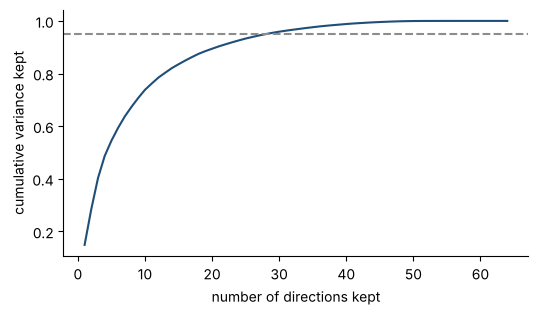

In [4]:
pca_full = PCA().fit(X)
cum = np.cumsum(pca_full.explained_variance_ratio_)
need = {t: int(np.searchsorted(cum, t) + 1) for t in [0.8, 0.9, 0.95, 0.99]}
print("directions needed to keep:", need)
print("share kept by the first 5 / 10 / 20:", [round(float(cum[i - 1]), 3) for i in (5, 10, 20)])
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(range(1, 65), cum, color=BLUE); ax.axhline(0.95, color=GRAY, ls="--")
ax.set_xlabel("number of directions kept"); ax.set_ylabel("cumulative variance kept")
plt.show()

**Giải thích từng dòng**

- `PCA().fit(X)`: không đặt `n_components` thì giữ hết 64 hướng, để xem toàn bộ dải.
- `np.cumsum(...)`: cộng dồn tỷ lệ: giữ `k` hướng đầu thì được bao nhiêu phần trăm.
- `np.searchsorted(cum, t) + 1`: tìm số hướng nhỏ nhất để vượt ngưỡng `t`.

**Cách đọc.**
- **Con số:** giữ **21** hướng được 90%, **29** hướng được 95%, **41** hướng được 99%, trên tổng 64 cột.
- **Bức tranh:** đường cong dốc ở đầu rồi thoải dần: vài hướng đầu giữ phần lớn thông tin, các hướng cuối chỉ giữ chút nhiễu. Có thể viết `PCA(n_components=0.95)` để sklearn tự chọn số hướng giữ 95%.
- **Quy tắc đọc:** ngưỡng 90 đến 95% là điểm khởi đầu, không phải luật. Thước đo thật là *mô hình sau nén còn làm tốt việc của nó không* (chặng 5).
- **Câu hỏi tiếp:** "mất 5% thông tin" nhìn bằng mắt thì thế nào?

**Mang về chặng 3:** vài chục hướng giữ gần hết thông tin của 64 cột.

## Chặng 3: Dựng lại ảnh từ ít hướng

**Câu hỏi:** nén rồi giải nén, chữ số còn đọc được không?

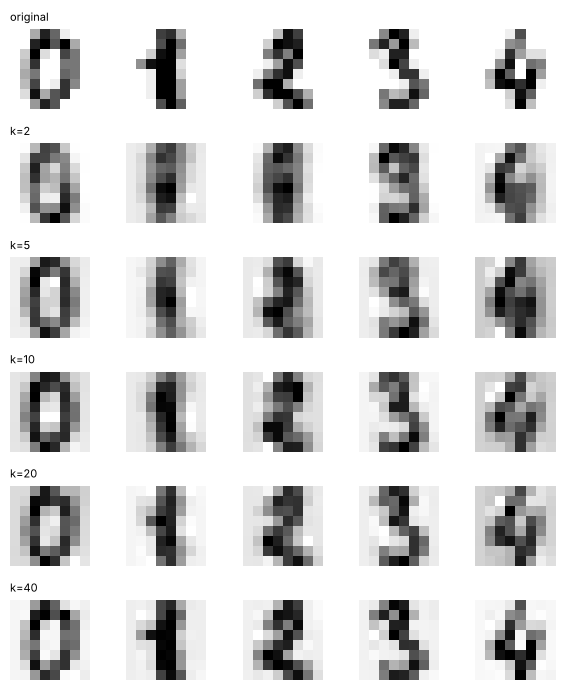

mean absolute pixel error by k: {2: 2.367, 5: 1.801, 10: 1.404, 20: 0.947, 40: 0.215}


In [5]:
sample = X[:5]
ks = [2, 5, 10, 20, 40]
fig, ax = plt.subplots(len(ks) + 1, 5, figsize=(6, 7))
for j in range(5):
    ax[0, j].imshow(sample[j].reshape(8, 8), cmap="gray_r"); ax[0, j].axis("off")
ax[0, 0].set_title("original", fontsize=8, loc="left")
errors = {}
for i, k in enumerate(ks, start=1):
    p = PCA(n_components=k).fit(X)
    back = p.inverse_transform(p.transform(sample))
    errors[k] = round(float(np.abs(back - sample).mean()), 3)
    for j in range(5):
        ax[i, j].imshow(back[j].reshape(8, 8), cmap="gray_r"); ax[i, j].axis("off")
    ax[i, 0].set_title(f"k={k}", fontsize=8, loc="left")
plt.tight_layout(); plt.show()
print("mean absolute pixel error by k:", errors)

**Giải thích từng dòng**

- `PCA(n_components=k).fit(X)`: học `k` hướng từ toàn bộ ảnh.
- `p.transform(sample)`: nén 5 ảnh mẫu: 64 số thành `k` số.
- `p.inverse_transform(...)`: giải nén: từ `k` số dựng lại 64 điểm ảnh. Không thể khôi phục hoàn toàn vì phần ngoài `k` hướng đã bỏ.
- `np.abs(back - sample).mean()`: sai số trung bình mỗi điểm ảnh (độ sáng từ 0 đến 16).

**Cách đọc.**
- **Con số:** sai số trung bình mỗi điểm ảnh giảm từ **2,37** (k=2) xuống **0,21** (k=40).
- **Bức tranh:** với k=2 ảnh dựng lại mờ, các chữ số 1, 2, 3 gần như giống nhau; k=10 đã đoán được chữ số nhưng còn nhòe; k=20 khá rõ; k=40 gần như giống ảnh gốc. Phần PCA bỏ đi chủ yếu là chi tiết nhỏ và nhiễu.
- **Ứng dụng:** nén ảnh, khử nhiễu (nén rồi giải nén thì nhiễu nhỏ rơi mất), và lưu trữ gọn.

**Mang về chặng 4:** nhìn ảnh dựng lại là cách kiểm tra trực quan nhất xem nén có quá tay không.

## Chặng 4: Bẫy thang đo

**Câu hỏi:** PCA có công bằng với mọi cột không?

In [6]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
wine = load_wine(as_frame=True)
W = wine.data
raw_p = PCA(n_components=2).fit(W)
sc_p = PCA(n_components=2).fit(StandardScaler().fit_transform(W))
load_raw = pd.Series(raw_p.components_[0], index=W.columns).abs().sort_values(ascending=False)
load_sc = pd.Series(sc_p.components_[0], index=W.columns).abs().sort_values(ascending=False)
print("PC1 share, raw:", round(raw_p.explained_variance_ratio_[0], 3), "| standardized:", round(sc_p.explained_variance_ratio_[0], 3))
print("top-2 columns in PC1, raw:", load_raw.head(2).round(3).to_dict())
print("top-2 columns in PC1, standardized:", load_sc.head(2).round(3).to_dict())
print("column std, largest vs smallest:", W.std().round(2).max(), "vs", W.std().round(2).min())

PC1 share, raw: 0.998 | standardized: 0.362
top-2 columns in PC1, raw: {'proline': 1.0, 'magnesium': 0.018}
top-2 columns in PC1, standardized: {'flavanoids': 0.423, 'total_phenols': 0.395}
column std, largest vs smallest: 314.91 vs 0.12


**Giải thích từng dòng**

- `load_wine(as_frame=True)`: 178 chai rượu vang, 13 chỉ số hóa học. Cột `proline` có giá trị hàng trăm đến hàng nghìn, các cột khác chỉ vài đơn vị.
- `StandardScaler().fit_transform(W)`: chuẩn hóa từng cột về trung bình 0, độ lệch 1.
- `raw_p.components_[0]`: "hệ số" của PC1: mỗi cột đóng góp bao nhiêu vào hướng đầu tiên. Lấy trị tuyệt đối để xếp hạng.

**Cách đọc.**
- **Con số:** PC1 giữ **99,8%** độ trải khi chưa chuẩn hóa và **36,2%** sau chuẩn hóa. Cột đóng góp nhiều nhất vào PC1 lúc chưa chuẩn hóa là **proline** (hệ số **1,000**).
- **Bức tranh:** PCA tìm hướng trải rộng nhất, mà cột có số to thì trải rộng nhất theo đơn vị của nó. Chưa chuẩn hóa thì PC1 gần như chỉ là cột `proline`. Chuẩn hóa xong, nhiều cột cùng góp.
- **Quy tắc đọc:** các cột khác đơn vị thì **luôn chuẩn hóa trước PCA** (như K-Means ở F1). Ảnh `digits` cùng thang 0 đến 16 nên không cần.

**Mang về chặng 5:** PCA chỉ công bằng khi các cột cùng thang đo.

## Chặng 5: PCA làm bước tiền xử lý

**Câu hỏi:** nén trước rồi mới học mô hình có làm mô hình tệ đi không?

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
import time
cv = StratifiedKFold(5, shuffle=True, random_state=0)
rows = []
for k in [2, 5, 10, 20, 30, 64]:
    t0 = time.time()
    pipe = make_pipeline(StandardScaler(), PCA(n_components=k), LogisticRegression(max_iter=2000))
    s = cross_val_score(pipe, X, y, cv=cv)
    rows.append({"directions": k, "accuracy": round(s.mean(), 4), "std": round(s.std(), 4), "seconds": round(time.time() - t0, 2)})
cls = pd.DataFrame(rows).set_index("directions")
print(cls.to_string())

            accuracy     std  seconds
directions                           
2             0.5404  0.0200     0.24
5             0.8114  0.0153     0.19
10            0.8843  0.0138     0.24
20            0.9421  0.0089     0.18
30            0.9538  0.0136     0.19
64            0.9694  0.0099     0.19


**Giải thích từng dòng**

- `make_pipeline(StandardScaler(), PCA(n_components=k), LogisticRegression())`: chuẩn hóa → nén xuống `k` hướng → logistic. PCA nằm **trong** pipeline nên mỗi vòng kiểm định chéo tự học lại PCA từ phần học (không rò rỉ, như D3).
- `cross_val_score(pipe, X, y, cv=cv)`: kiểm định chéo 5 vòng cho độ chính xác và độ lệch.
- `time.time()`: đo thời gian để thấy nén có đỡ tốn không.

**Cách đọc.**
- **Con số:** với 2 hướng độ chính xác chỉ **54,0%**; 10 hướng **88,4%**; 20 hướng **94,2%**; đủ 64 cột **96,9%** (độ lệch cỡ 1,0%).
- **Bức tranh:** nén xuống khoảng 20 đến 30 hướng cho độ chính xác thấp hơn một chút so với dùng đủ 64 cột. Nén quá tay (2 đến 5 hướng) thì mất rõ.
- **Quy tắc đọc:** số hướng giữ là một siêu tham số như mọi cái khác: chọn bằng kiểm định chéo (D1, D4), không chọn theo 95% rồi tin. Với dữ liệu nhỏ và mô hình nhanh như thế này, PCA không đem lại lợi lớn; lợi lớn nằm ở dữ liệu hàng trăm cột hoặc mô hình chậm.
- **Lưu ý:** PCA tạo cột mới (tổ hợp của cột cũ) nên **khó giải thích** hơn cột gốc. Cần giải thích cho người ra quyết định thì cân nhắc.

**Mang về:** chuẩn hóa → PCA trong pipeline → chọn số hướng bằng kiểm định chéo.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | PCA nén nhiều cột thành vài cột mà không cần nhãn; vẽ được 2D. |
| 1 | PCA = tâm hóa, hiệp phương sai, hướng riêng lớn nhất. |
| 2 | Chọn số hướng theo tỷ lệ giải thích cộng dồn, rồi kiểm lại bằng mô hình. |
| 3 | Dựng lại ảnh để thấy tận mắt phần mất. |
| 4 | Chuẩn hóa trước PCA khi các cột khác đơn vị. |
| 5 | PCA nằm trong pipeline; số hướng chọn bằng kiểm định chéo. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Góc chụp cho thấy rõ nhất hình chiếc bàn | thành phần chính | `PCA` |
| Bao nhiêu phần ý chính còn giữ lại | tỷ lệ phương sai giải thích | `explained_variance_ratio_` |
| Hướng nhìn | hướng riêng, hệ số | `components_` |
| Nén xuống vài số | chiếu | `transform` |
| Giải nén lại | dựng lại | `inverse_transform` |
| Giữ đủ 95% thông tin | chọn theo tỷ lệ | `PCA(n_components=0.95)` |

**Thử thách tự làm**

1. Ở chặng 2, dùng `PCA(n_components=0.95)` rồi in `n_components_`. Có khớp con số `need[0.95]` không?
2. Ở chặng 3, thử k = 1. Ảnh dựng lại trông thế nào và vì sao?
3. Ở chặng 5, thay `LogisticRegression` bằng `KNeighborsClassifier`. Số hướng tối ưu có đổi không?
4. Vẽ ảnh 8x8 của `pca2.components_[0]` và `components_[1]`. Hai hướng đầu "nhìn" vào đâu?

**Checklist năng lực** (tự tick khi làm được)

- [ ] Giải thích PCA bằng ví dụ góc chụp.
- [ ] Tự tính PCA từ ma trận hiệp phương sai.
- [ ] Chọn số hướng bằng đường cộng dồn và kiểm định chéo.
- [ ] Biết phải chuẩn hóa trước PCA.
- [ ] Đặt PCA trong pipeline để tránh rò rỉ.

## Phần thưởng (Tip pro): PCA tuyến tính, còn dữ liệu cong thì sao


PCA chỉ tìm hướng **thẳng**. Dữ liệu cuộn như cuộn bánh thì các hướng thẳng không mở được nó ra. Buổi F5 dạy t-SNE, một cách vẽ 2D khác, giữ các điểm hàng xóm gần nhau.